In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster


In [2]:
df = pd.read_csv('../data/processed/board_games_clean.csv')

In [3]:
df_train = df.copy()

In [4]:
#droppo le colonne non utili ai fini dello hierarchical clustering
df_train = df_train.drop(columns = ['BGGId', 'Name','NumAlternates'])

In [5]:
#droppo anche le colonne che iniziano con Rank
df_train = df_train.drop(columns = [col for col in df_train.columns if col.startswith('Rank')])


In [6]:
#In quanto non sono stati ottenuti risultati soddisfacenti con tutte le features, provo a eliminare le colonne delle categorie
df_train = df_train.drop(columns = [col for col in df_train.columns if col.startswith('Cat:')])


In [7]:
#Non ho ottenuto risultati soddisfacenti nemmeno senza le categorie, elimino le altre colonne binarie, colonne con molti zeri, e languageease
#che impatta veramente poco sulla formazione dei clusters
df_train = df_train.drop(columns = ['IsReimplementation', 'Kickstarted', 'belong_to_family','NumImplementations','NumExpansions','LanguageEase'])

###Ho rimosso le variabili sparse e binarie perché la Distanza Euclidea usata da K-Means e Ward soffre della 'maledizione della dimensionalità' in presenza di dati non continui. Queste variabili introducevano rumore e forzavano i cluster in strutture geometriche rigide, impedendo di rilevare la reale densità dei dati.

In [8]:
#le colonne minplayers e maxplayers portano alla creazione di un cluster molto poco significativo e molto piccolo, di conseguenza le elimino
df_train = df_train.drop(columns = ['MaxPlayers', 'MinPlayers'])

In [9]:
#Avendo già comagerec, elimino la clonna mfgagerec essendo due colonne con una finalità simile
df_train = df_train.drop(columns = ['MfgAgeRec'])

In [10]:
df_train.head()

,YearPublished,ComWeight,ComAgeRec,NumOwned,NumWish,NumWeightVotes,ComMinPlaytime,ComMaxPlaytime,Rating
0,2014,2.0512,8,6.270988,4.174387,1.945910,3.433987,3.433987,1
1,2021,1.2256,8,4.290459,3.871201,1.945910,2.772589,3.044522,2
2,2020,3.8190,10,6.727432,4.158883,2.302585,3.433987,5.017280,3
3,2004,1.4216,7,5.043425,2.079442,2.639057,3.044522,3.044522,1
4,2019,1.6230,10,5.342334,3.583519,1.098612,2.772589,3.044522,2


In [11]:
#Uso lo standard scaler perchè più robusto agli outlier, più stabile con alta dimensinalità
scaler = StandardScaler()
df_train_scaled = pd.DataFrame(scaler.fit_transform(df_train), columns=df_train.columns)
df_train_scaled.head()

,YearPublished,ComWeight,ComAgeRec,NumOwned,NumWish,NumWeightVotes,ComMinPlaytime,ComMaxPlaytime,Rating
0,0.522349,-0.189195,-0.739723,0.158887,0.154455,-0.470441,-0.300000,-0.563423,-1.231177
1,1.073850,-1.217397,-0.739723,-1.286081,-0.033212,-0.470441,-1.073758,-1.012963,0.123229
2,0.995064,2.012423,-0.045234,0.491902,0.144858,-0.211023,-0.300000,1.264092,1.477635
3,-0.265508,-0.973299,-1.086967,-0.736727,-1.142281,0.033701,-0.755628,-1.012963,-1.231177
4,0.916278,-0.722475,-0.045234,-0.518647,-0.211283,-1.086700,-1.073758,-1.012963,0.123229


###APPLICO IL K MEANS PER DIMINUIRE LA DIMENSIONALITà, IN MODO DA RENDERE FATTIBILE LO HIERARCHICAL CLUSTERING E RENDERE LEGGIBILE IL DENDROGRAMMA

In [12]:
from sklearn.metrics import pairwise_distances_argmin_min

In [13]:
# 1. Eseguiamo K-Means 
k = 2000
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(df_train_scaled)

# Questi sono i centroidi "sintetici" (medie matematiche), da non usare perchè non rappresentano punti reali del dataset
centroidi_sintetici = kmeans.cluster_centers_

# argmin_min restituisce l'indice del punto più vicino nel dataset originale
indici_punti_reali, _ = pairwise_distances_argmin_min(centroidi_sintetici, df_train_scaled)

# 3. Estraiamo i record reali dal tuo DataFrame originale
punti_rappresentativi_reali = df_train_scaled.iloc[indici_punti_reali]

print(f"Trovati {k} punti reali rappresentativi dei cluster.")

Trovati 2000 punti reali rappresentativi dei cluster.


In [14]:
df_train_scaled.head()

,YearPublished,ComWeight,ComAgeRec,NumOwned,NumWish,NumWeightVotes,ComMinPlaytime,ComMaxPlaytime,Rating
0,0.522349,-0.189195,-0.739723,0.158887,0.154455,-0.470441,-0.300000,-0.563423,-1.231177
1,1.073850,-1.217397,-0.739723,-1.286081,-0.033212,-0.470441,-1.073758,-1.012963,0.123229
2,0.995064,2.012423,-0.045234,0.491902,0.144858,-0.211023,-0.300000,1.264092,1.477635
3,-0.265508,-0.973299,-1.086967,-0.736727,-1.142281,0.033701,-0.755628,-1.012963,-1.231177
4,0.916278,-0.722475,-0.045234,-0.518647,-0.211283,-1.086700,-1.073758,-1.012963,0.123229


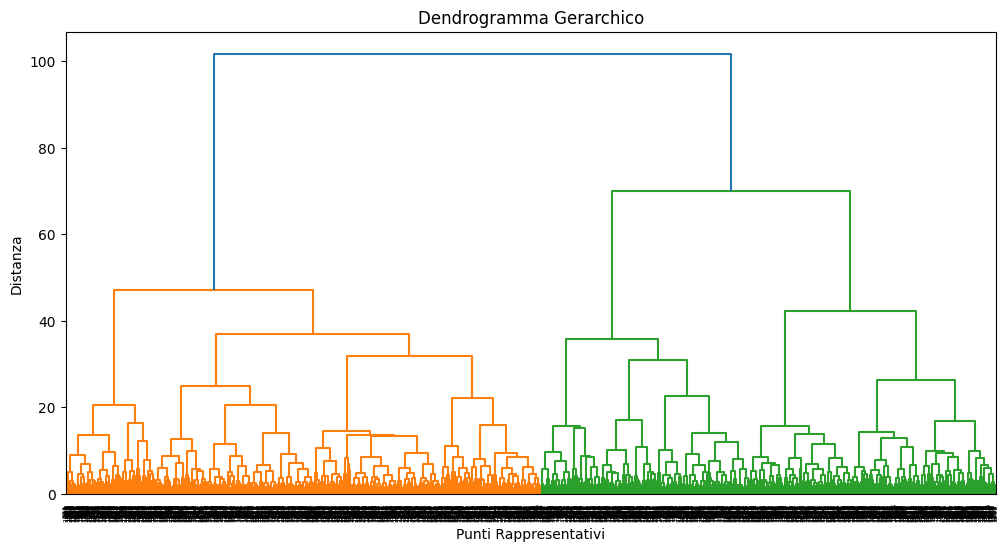

In [15]:
Z = linkage(punti_rappresentativi_reali, method='ward', metric='euclidean')
plt.figure(figsize=(12, 6))
dendrogram(Z)
plt.title('Dendrogramma Gerarchico')
plt.xlabel('Punti Rappresentativi')
plt.ylabel('Distanza')
plt.show()

In [16]:
# Estraiamo 3 cluster
cluster_3 = fcluster(Z, t=6, criterion='maxclust')

# Ora aggiungiamo queste etichette ai 2000 punti reali per l'analisi
punti_rappresentativi_reali = punti_rappresentativi_reali.copy()
punti_rappresentativi_reali['gerarchico_3'] = cluster_3



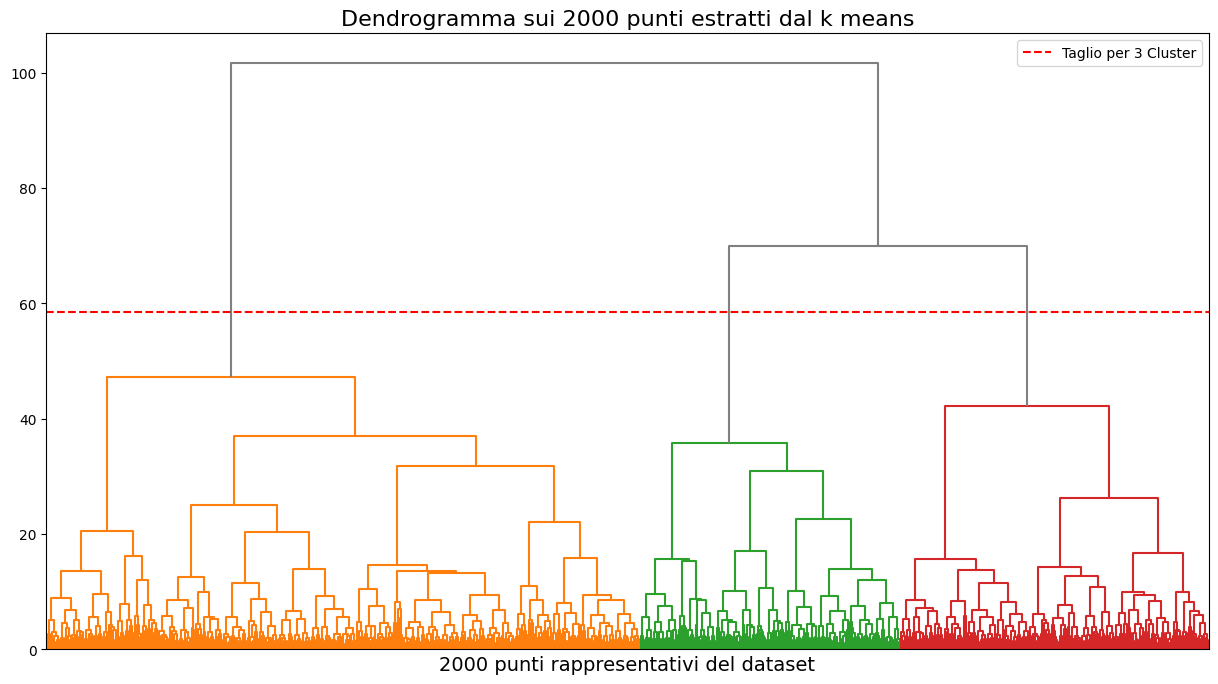

In [17]:
# Calcolo della soglia per colorare esattamente 3 cluster
distanze = Z[:, 2]
soglia = (distanze[-3] + distanze[-2]) / 2

# 2. Creazione del grafico
plt.figure(figsize=(15, 8))

# Disegniamo il dendrogramma completo
dn = dendrogram(
    Z,
    color_threshold=soglia, 
    no_labels=True,          
    above_threshold_color='grey' 
)

# 3. Aggiunta della linea di taglio visiva
plt.axhline(y=soglia, color='r', linestyle='--', label=f'Taglio per 3 Cluster')

plt.title('Dendrogramma sui 2000 punti estratti dal k means', fontsize=16)
plt.xlabel('2000 punti rappresentativi del dataset', fontsize=14)
plt.legend()
plt.show()

In [18]:
# Estraiamo le etichette per i 2000 punti reali (valori da 1 a 3)
etichette_gerarchico = fcluster(Z, t=3, criterion='maxclust')

# Creiamo un dizionario: {Indice_Cluster_KMeans: Macro_Cluster_Gerarchico}
# Poiché i 2000 punti reali rappresentano i cluster 0-1999 del KMeans:
mappa_macro_cluster = {i: etichette_gerarchico[i] for i in range(len(etichette_gerarchico))}

In [19]:
# 1. Assicurati che nel DataFrame ci siano le etichette originali del KMeans
df_train_scaled['cluster_kmeans'] = kmeans.labels_

# 2. Creiamo la colonna finale mappando i 2000 cluster sui 3 macro-cluster
df_train_scaled['cluster_finale_gerarchico'] = df_train_scaled['cluster_kmeans'].map(mappa_macro_cluster)

# Verifichiamo la distribuzione finale sui 20.773 punti
print("Distribuzione finale dei punti nei 3 macro-cluster:")
print(df_train_scaled['cluster_finale_gerarchico'].value_counts().sort_index())

Distribuzione finale dei punti nei 3 macro-cluster:
cluster_finale_gerarchico
1    11565
2     4644
3     4564
Name: count, dtype: int64


In [20]:
df_train_scaled = df_train_scaled.drop(columns=['cluster_kmeans'])

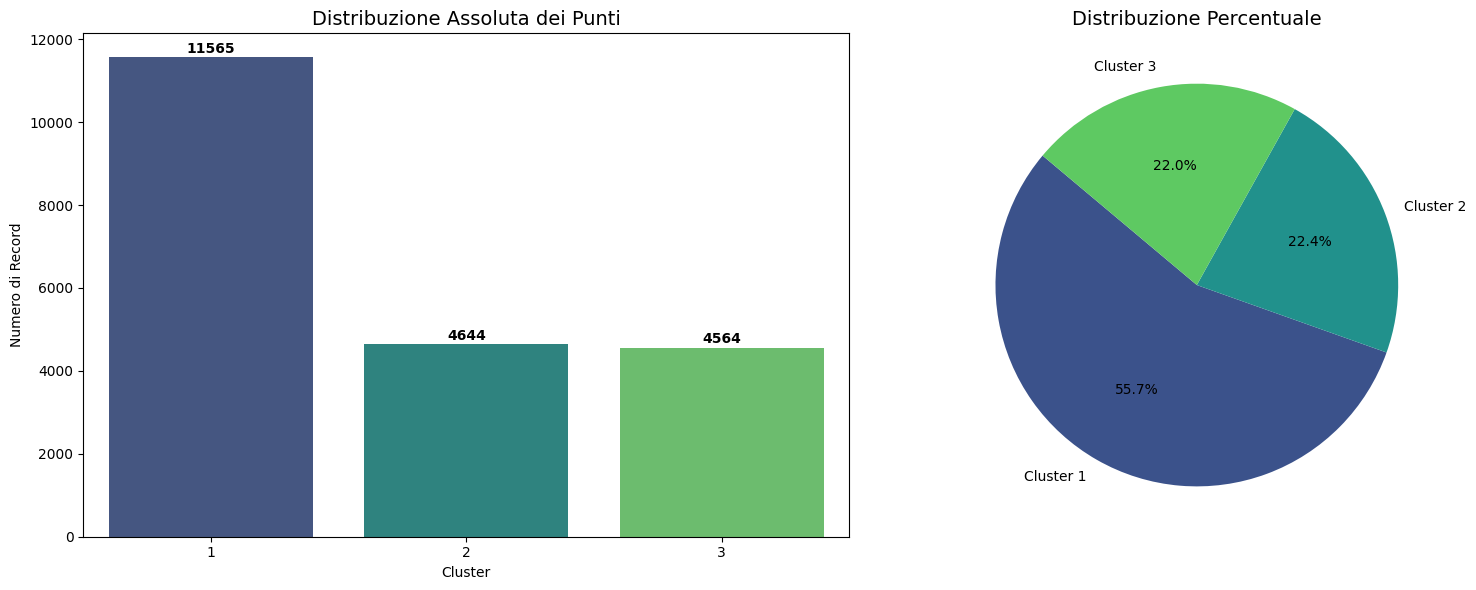

In [21]:
# 1. Prepariamo i dati
conteggi = df_train_scaled['cluster_finale_gerarchico'].value_counts().sort_index()
percentuali = df_train_scaled['cluster_finale_gerarchico'].value_counts(normalize=True).sort_index() * 100

# 2. Creiamo la figura con due grafici (Subplots)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# GRAFICO A BARRE (Quantità assolute)
sns.barplot(x=conteggi.index, y=conteggi.values, ax=ax[0], palette='viridis')
ax[0].set_title('Distribuzione Assoluta dei Punti', fontsize=14)
ax[0].set_xlabel('Cluster')
ax[0].set_ylabel('Numero di Record')
# Aggiungiamo il numero esatto sopra ogni barra
for i, v in enumerate(conteggi.values):
    ax[0].text(i, v + 100, str(v), ha='center', fontweight='bold')

# GRAFICO A TORTA (Percentuali)
ax[1].pie(percentuali, labels=[f'Cluster {i}' for i in percentuali.index], 
        autopct='%1.1f%%', startangle=140, colors=sns.color_palette('viridis', len(percentuali)))
ax[1].set_title('Distribuzione Percentuale', fontsize=14)

plt.tight_layout()
plt.show()

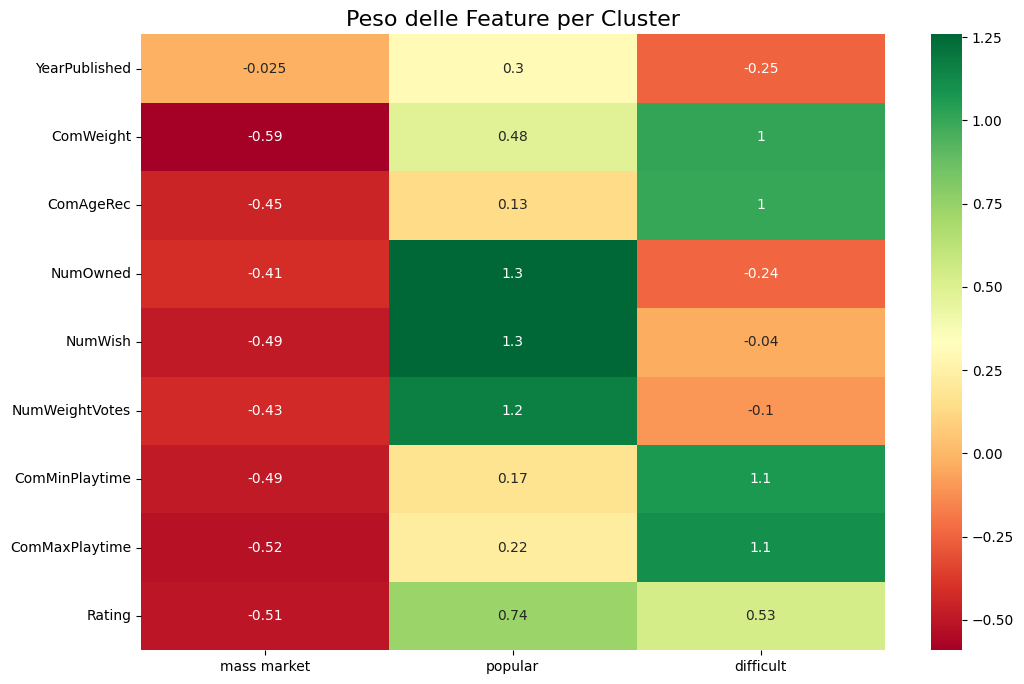

In [22]:
# Analisi media delle feature per cluster (profilazione)
analisi_media = df_train_scaled.groupby('cluster_finale_gerarchico').mean()

nomi_cluster = ['mass market', 'popular', 'difficult']
# 2. Assegna i nomi alle colonne del DataFrame trasposto o rinomina l'indice prima del groupby
analisi_media.index = nomi_cluster

# 3. Plot (senza modifiche ulteriori agli assi)
plt.figure(figsize=(12, 8))
sns.heatmap(analisi_media.T, cmap='RdYlGn', annot=True, cbar=True)
plt.title('Peso delle Feature per Cluster', fontsize=16)
plt.show()

In [23]:
#calcolo il silhouette score per valutare la bontà del clustering gerarchico
silhouette_avg = silhouette_score(df_train_scaled.drop(columns=['cluster_finale_gerarchico']), df_train_scaled['cluster_finale_gerarchico'])
print(f'Silhouette Score del clustering gerarchico: {silhouette_avg:.4f}')






Silhouette Score del clustering gerarchico: 0.2254


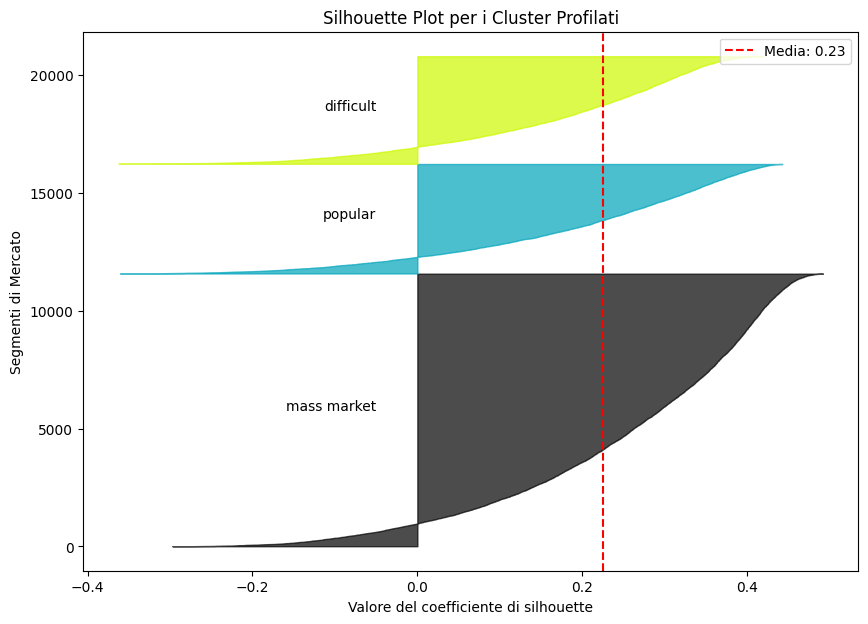

In [ ]:
# 1. Definisci la mappatura (assicurati che le chiavi corrispondano ai tuoi ID cluster)
from sklearn.metrics import silhouette_samples, silhouette_score

import matplotlib.cm as cm

import numpy as np
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.cm as cm
import numpy as np
import matplotlib.pyplot as plt

# 1. DEFINIZIONE DELLE VARIABILI MANCANTI
# Estraiamo le etichette dei cluster dal DataFrame (assicurati che il nome della colonna sia corretto)
cluster_labels = df_train_scaled['cluster_finale_gerarchico'].values

# Definiamo X (il dataset scalato senza le colonne di cluster)
X = df_train_scaled.drop(columns=['cluster_finale_gerarchico', 'cluster_kmeans'], errors='ignore').values

# Calcoliamo i valori di silhouette per ogni punto
sample_silhouette_values = silhouette_samples(X, cluster_labels)

# 2. CONFIGURAZIONE GRAFICA
nomi_cluster = {1: 'mass market', 2: 'popular', 3: 'difficult'}
n_clusters = len(np.unique(cluster_labels))

fig, ax1 = plt.subplots(1, 1, figsize=(10, 7))
y_lower = 10

# 3. CICLO PER DISEGNARE I CLUSTER
for i in sorted(nomi_cluster.keys()):
    # Estraiamo e ordiniamo i valori per il cluster i
    ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
    ith_cluster_silhouette_values.sort()

    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    color = cm.nipy_spectral(float(i-1) / n_clusters)
    ax1.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_silhouette_values,
                      facecolor=color, edgecolor=color, alpha=0.7)

    # Inseriamo il nome del cluster sull'asse Y
    ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, nomi_cluster[i], ha='right')
    y_lower = y_upper + 10

# 4. LINEA MEDIA E TITOLI
avg_score = silhouette_score(X, cluster_labels)
ax1.axvline(x=avg_score, color="red", linestyle="--", label=f'Media: {avg_score:.2f}')

ax1.set_title("Silhouette Plot per i Cluster Profilati")
ax1.set_xlabel("Valore del coefficiente di silhouette")
plt.legend(loc="upper right")
plt.show()